# Jakarta air quality: basic preprocessing

This version uses basic pandas operations and Matplotlib graphs. Each data-changing cell displays a preview, a before/after summary, or a plot.

Steps: load the three sources, remove duplicates and invalid air measurements, average readings by hour, clean weather values, select one nearby weather station, merge by UTC hour, and check correlated weather columns. Missing weather values stay missing. There is no interpolation, per-sensor distance calculation, PCA, or spreadsheet export in this version.

The same nearby station supplies city-level weather context for all air sensors; it does not represent the exact weather at each sensor. Saved data are used by default, so the notebook can run without API requests.

Sources: [OpenAQ](https://docs.openaq.org/), [PurpleAir](https://api.purpleair.com/), [Meteostat](https://dev.meteostat.net/python/api/meteostat.hourly).

The accompanying article describes this simplified version.

In [1]:
import os
import json
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import meteostat as ms

In [2]:
#API and variable set up

# API keys are listed outside of the notebook (api_keys.txt)
def load_api_keys(path="api_keys.txt"):    
    keys = {}
    if not Path(path).exists():
        return keys
    for raw in Path(path).read_text(encoding="utf-8").splitlines():
        line = raw.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        name, value = line.split("=", 1)
        keys[name.strip()] = value.strip()
    return keys

_API_KEYS = load_api_keys()
OPENAQ_API_KEY = _API_KEYS.get("OPENAQ_API_KEY", os.getenv("OPENAQ_API_KEY", ""))
PURPLEAIR_READ_KEY = _API_KEYS.get("PURPLEAIR_READ_KEY", os.getenv("PURPLEAIR_READ_KEY", ""))
USE_SAVED_DATA = True
SNAPSHOT_DIR = "data/air_quality_snapshot"

In [3]:
#Coordinates and Time Variables
WEST, SOUTH, EAST, NORTH = 106.689, -6.370, 106.978, -6.079
JAKARTA_LAT, JAKARTA_LON = -6.2088, 106.8456

START_DATE = "2024-01-01 00:00:00+07:00"
END_DATE = "2024-02-01 00:00:00+07:00"

START_UTC = pd.Timestamp(START_DATE).tz_convert("UTC")
END_UTC = pd.Timestamp(END_DATE).tz_convert("UTC")
# Using universal (UTC) time for all data requests
if START_UTC >= END_UTC:
    raise ValueError("START_DATE must precede END_DATE")
AIR_COLUMNS = ["time", "source", "site_id", "latitude", "longitude", "pm25"]

In [4]:
# Universal API data getter: stop on failure
def get_api_data(url, headers=None, params=None):
    if USE_SAVED_DATA:
        archive = Path(SNAPSHOT_DIR) / "raw_responses"
        manifest = json.loads((archive / "manifest.json").read_text(encoding="utf-8"))
        # Try exact match first (URL + all params equal)
        match = next((entry for entry in manifest if entry["url"] == url and entry["params"] == params), None)
        if match is None:
            # Helpful diagnostics: show params for same-URL entries
            same_url = [e for e in manifest if e["url"] == url]
            hint_lines = [f"Request not in saved snapshot:\n  url={url}\n  requested params={params}"]
            if same_url:
                hint_lines.append(f"  Same URL has {len(same_url)} saved entry/entries with params:")
                for e in same_url[:3]:
                    hint_lines.append(f"    - {e['params']}")
            else:
                hint_lines.append(f"  No saved entries with this URL. Available URLs:")
                for u in sorted(set(e['url'] for e in manifest)):
                    hint_lines.append(f"    - {u}")
            hint_lines.append("Use the original settings (START/END dates, bbox, parameters_id) or set USE_SAVED_DATA=False.")
            raise ValueError("\n".join(hint_lines))
        response_text = (archive / match["file"]).read_text(encoding="utf-8")
        return json.loads(response_text)
    response = requests.get(url, headers=headers, params=params, timeout=30)
    response.raise_for_status()
    result = response.json()
    if not isinstance(result, dict) or result.get("error"):
        raise RuntimeError(f"Invalid API response from {url}")
    return result


def key_is_ready(key):
    return bool(key) and not key.startswith("PASTE_")


def get_openaq_results(url, headers, params):
    rows = []
    page = 1
    while True:
        result = get_api_data(url, headers, {**params, "page": page})
        batch = result["results"]
        rows.extend(batch)
        if len(batch) < params["limit"]:
            return rows
        page += 1


In [5]:
#Download OpenAQ

def download_openaq():
    if not USE_SAVED_DATA and not key_is_ready(OPENAQ_API_KEY):
        raise ValueError("Set OPENAQ_API_KEY before downloading")
    headers = {"X-API-Key" : OPENAQ_API_KEY}
    location_url = "https://api.openaq.org/v3/locations"
    location_params = {
        "bbox": f"{WEST},{SOUTH},{EAST},{NORTH}",
        "parameters_id" : 2,
        "limit": 1000 
    }

    locations = get_openaq_results(location_url, headers, location_params)

    sensors = []
    for location in locations:
        if location.get("isMobile") is True:
            continue

        coordinates = location.get("coordinates") or {}
        for sensor in location.get("sensors", []):
            parameter = sensor.get("parameter") or {}
            if parameter.get("id") == 2:
                sensors.append(
                    {
                        "sensor_id": sensor["id"],
                        "latitude": coordinates.get("latitude"),
                        "longitude": coordinates.get("longitude"),
                    }
                )

    sensors = pd.DataFrame(sensors, columns=["sensor_id", "latitude", "longitude"]).drop_duplicates("sensor_id")
    print("OpenAQ sensors:", len(sensors))

    rows = []
    for sensor in sensors.itertuples(index=False):
        url = f"https://api.openaq.org/v3/sensors/{sensor.sensor_id}/hours"
        params = {
            "datetime_from": START_UTC.isoformat(),
            "datetime_to": END_UTC.isoformat(),
            "limit": 1000,
        }
        measurements = get_openaq_results(url, headers, params)

        for item in measurements:
            period = item.get("period") or {}
            start = period.get("datetimeFrom") or {}
            rows.append(
                {
                    "time": start.get("utc"),
                    "source": "OpenAQ",
                    "site_id": f"OpenAQ_{sensor.sensor_id}",
                    "latitude": sensor.latitude,
                    "longitude": sensor.longitude,
                    "pm25": item.get("value"),
                }
            )

    return pd.DataFrame(rows, columns=AIR_COLUMNS)


openaq_raw = download_openaq()
print("OpenAQ rows:", len(openaq_raw))
display(openaq_raw.head())

OpenAQ sensors: 20
OpenAQ rows: 3990


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31T17:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31T18:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31T19:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31T20:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31T21:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


In [6]:
#Download PurpleAir

def purpleair_dataframe(result):
    return pd.DataFrame(result.get("data", []), columns=result.get("fields", []))

def download_purpleair():
    if not USE_SAVED_DATA and not key_is_ready(PURPLEAIR_READ_KEY):
        raise ValueError("Set PURPLEAIR_READ_KEY before downloading")
    headers = {"X-API-Key": PURPLEAIR_READ_KEY}
    sensor_url = "https://api.purpleair.com/v1/sensors"
    sensor_params = {
        "fields": "name,latitude,longitude,location_type",
        "location_type": 0,
        "max_age": 0,  # Include sensors which are no longer reporting.
        "nwlat": NORTH,
        "nwlng": WEST,
        "selat": SOUTH,
        "selng": EAST,
    }

    result = get_api_data(sensor_url, headers, sensor_params)
    sensors = purpleair_dataframe(result)
    print("PurpleAir sensors:", len(sensors))

    all_rows = []
    for sensor in sensors.itertuples(index=False):
        # One-hour averages for the selected month.
        history_url = (
            f"https://api.purpleair.com/v1/sensors/"
            f"{sensor.sensor_index}/history"
        )
        history_params = {
            "start_timestamp": int(START_UTC.timestamp()),
            "end_timestamp": int(END_UTC.timestamp()),
            "average": 60,
            "fields": "pm2.5_cf_1_a,pm2.5_cf_1_b",
        }

        result = get_api_data(history_url, headers, history_params)
        history = purpleair_dataframe(result)

        if history.empty:
            continue

        history["time"] = pd.to_datetime(history["time_stamp"], unit="s", utc=True)
        history["source"] = "PurpleAir"
        history["site_id"] = f"PurpleAir_{sensor.sensor_index}"
        history["latitude"] = sensor.latitude
        history["longitude"] = sensor.longitude
        all_rows.append(history)

    if not all_rows:
        return pd.DataFrame()

    return pd.concat(all_rows, ignore_index=True)


purpleair_raw = download_purpleair()
print("PurpleAir rows:", len(purpleair_raw))
display(purpleair_raw.head())

PurpleAir sensors: 12
PurpleAir rows: 2906


,time_stamp,pm2.5_cf_1_a,pm2.5_cf_1_b,time,source,site_id,latitude,longitude
0,1706666400,43.0,30.7,2024-01-31 02:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
1,1706342400,32.0,22.2,2024-01-27 08:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
2,1706371200,56.0,40.0,2024-01-27 16:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
3,1706360400,69.4,49.0,2024-01-27 13:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
4,1706353200,45.2,31.7,2024-01-27 11:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121


In [7]:
#Download weather data from meteostat
def download_weather():
    if USE_SAVED_DATA:
        station_query = pd.read_csv(Path(SNAPSHOT_DIR) / "Stations_downloaded.csv", dtype={"id": str}).set_index("id")
        weather = pd.read_csv(Path(SNAPSHOT_DIR) / "Weather_downloaded.csv", dtype={"station": str})
        weather["time"] = pd.to_datetime(weather["time"], utc=True)
    else:
        point = ms.Point(JAKARTA_LAT, JAKARTA_LON)
        station_query = ms.stations.nearby(point, limit=5)
        if station_query.empty:
            raise ValueError("No nearby weather stations found")
        start = START_UTC.tz_localize(None).to_pydatetime()
        end = END_UTC.tz_localize(None).to_pydatetime()
        weather = ms.hourly(station_query, start, end, timezone="UTC").fetch().reset_index()


    stations = station_query.rename_axis("station_id").reset_index().rename(
        columns={
            "id": "station_id",
            "latitude": "station_latitude",
            "longitude": "station_longitude",
        }
    )

    weather = weather.rename(
        columns={
            "station": "station_id",
            "time": "time",
            "temp": "temperature",
            "rhum": "humidity",
            "prcp": "rain",
            "wspd": "wind_speed",
            "pres": "pressure",
        }
    )

    weather["station_id"] = weather["station_id"].astype(str)
    stations["station_id"] = stations["station_id"].astype(str)
    weather["time"] = pd.to_datetime(weather["time"], utc=True)

    weather = weather.loc[weather["time"].ge(START_UTC) & weather["time"].lt(END_UTC)].copy()
    if weather.empty:
        raise ValueError("No weather observations for the selected period")
    return stations, weather


weather_stations, weather = download_weather()

print("Weather stations:", len(weather_stations))
display(weather.head())
weather_raw = weather.copy()

Weather stations: 5


,station_id,time,temperature,humidity,rain,snwd,wdir,wind_speed,wpgt,pressure,tsun,cldc,coco
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,NaN,78,6.1,NaN,1010.8,NaN,8,3.0
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,NaN,0,0.0,NaN,1010.4,NaN,7,3.0
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,NaN,3,6.8,NaN,1010.5,NaN,8,8.0
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,NaN,132,6.1,NaN,1009.5,NaN,8,7.0
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,NaN,0,0.0,NaN,1009.6,NaN,7,3.0


In [8]:
# Clean OpenAQ: remove exact duplicates and invalid PM2.5 readings.
openaq_clean = openaq_raw.drop_duplicates().copy()
openaq_clean["time"] = pd.to_datetime(openaq_clean["time"], utc=True, errors="coerce")
openaq_clean["pm25"] = pd.to_numeric(openaq_clean["pm25"], errors="coerce")
openaq_clean = openaq_clean.loc[openaq_clean["pm25"].between(0, 1000)].dropna(subset=["time"])

print("OpenAQ rows before / after:", len(openaq_raw), "/", len(openaq_clean))
print("Before:")
display(openaq_raw.head())
print("After:")
display(openaq_clean.head())

OpenAQ rows before / after: 3990 / 3254
Before:


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31T17:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31T18:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31T19:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31T20:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31T21:00:00Z,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


After:


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31 17:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31 18:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31 19:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31 20:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31 21:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


In [9]:
# Clean PurpleAir: require two valid channels, then calculate their mean.
purpleair_clean = purpleair_raw.drop_duplicates().copy()
channels = ["pm2.5_cf_1_a", "pm2.5_cf_1_b"]
for column in channels:
    purpleair_clean[column] = pd.to_numeric(purpleair_clean[column], errors="coerce")
purpleair_clean["time"] = pd.to_datetime(purpleair_clean["time"], utc=True, errors="coerce")
purpleair_clean["pm25"] = purpleair_clean[channels].mean(axis=1, skipna=False)
valid = purpleair_clean[channels[0]].between(0, 1000) & purpleair_clean[channels[1]].between(0, 1000)
# Keep the existing channel agreement rule: difference <= max(10, half the mean).
difference = (purpleair_clean[channels[0]] - purpleair_clean[channels[1]]).abs()
valid = valid & difference.le((purpleair_clean["pm25"] * 0.5).clip(lower=10))
print("Examples rejected by channel checks:")
display(purpleair_clean.loc[~valid, ["time"] + channels + ["pm25"]].head())
purpleair_clean = purpleair_clean.loc[valid, AIR_COLUMNS].dropna(subset=["time"])

print("PurpleAir rows before / after:", len(purpleair_raw), "/", len(purpleair_clean))
print("Before:")
display(purpleair_raw.head())
print("After:")
display(purpleair_clean.head())

Examples rejected by channel checks:


,time,pm2.5_cf_1_a,pm2.5_cf_1_b,pm25
2589,2024-01-18 13:00:00+00:00,9.7,47.0,28.35


PurpleAir rows before / after: 2906 / 2905
Before:


,time_stamp,pm2.5_cf_1_a,pm2.5_cf_1_b,time,source,site_id,latitude,longitude
0,1706666400,43.0,30.7,2024-01-31 02:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
1,1706342400,32.0,22.2,2024-01-27 08:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
2,1706371200,56.0,40.0,2024-01-27 16:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
3,1706360400,69.4,49.0,2024-01-27 13:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121
4,1706353200,45.2,31.7,2024-01-27 11:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121


After:


,time,source,site_id,latitude,longitude,pm25
0,2024-01-31 02:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121,36.85
1,2024-01-27 08:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121,27.10
2,2024-01-27 16:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121,48.00
3,2024-01-27 13:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121,59.20
4,2024-01-27 11:00:00+00:00,PurpleAir,PurpleAir_55391,-6.124591,106.85121,38.45


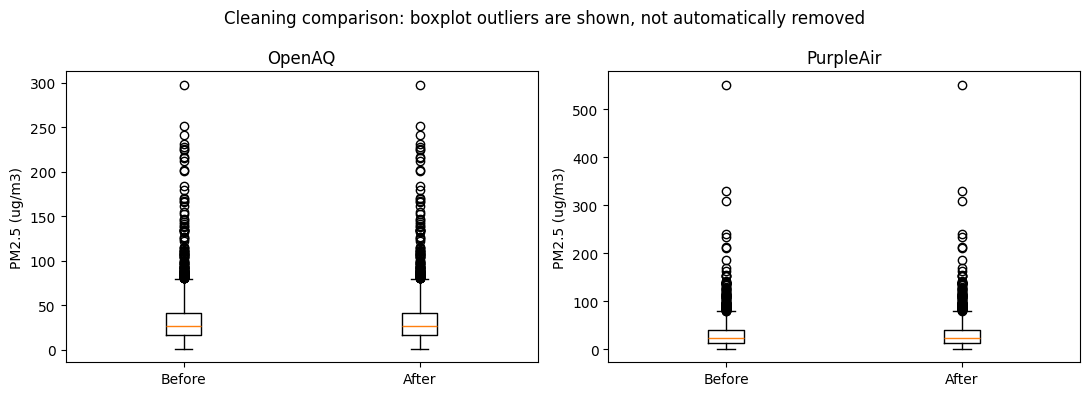

In [10]:
# Compare the distributions before and after cleaning.
raw_purple_pm25 = purpleair_raw[channels].apply(pd.to_numeric, errors="coerce").mean(axis=1, skipna=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, before, after in [
    (axes[0], "OpenAQ", pd.to_numeric(openaq_raw["pm25"], errors="coerce"), openaq_clean["pm25"]),
    (axes[1], "PurpleAir", raw_purple_pm25, purpleair_clean["pm25"]),
]:
    ax.boxplot([before.dropna(), after.dropna()], tick_labels=["Before", "After"])
    ax.set(title=name, ylabel="PM2.5 (ug/m3)")
fig.suptitle("Cleaning comparison: boxplot outliers are shown, not automatically removed")
plt.tight_layout()
plt.show()

In [11]:
# Combine air data and keep valid locations inside the selected area and period.
air_data = pd.concat([openaq_clean, purpleair_clean], ignore_index=True)
rows_before = len(air_data)
print("Before filtering:")
display(air_data.head())
for column in ["latitude", "longitude"]:
    air_data[column] = pd.to_numeric(air_data[column], errors="coerce")
air_data = air_data.dropna(subset=AIR_COLUMNS)
air_data = air_data.loc[
    air_data["time"].ge(START_UTC) & air_data["time"].lt(END_UTC)
    & air_data["latitude"].between(SOUTH, NORTH)
    & air_data["longitude"].between(WEST, EAST)
].copy()
if air_data.empty:
    raise ValueError("No valid air measurements in the selected area and period")
print("Combined rows before / after filtering:", rows_before, "/", len(air_data))
display(air_data.head())

Before filtering:


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31 17:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31 18:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31 19:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31 20:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31 21:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


Combined rows before / after filtering: 6159 / 6159


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31 17:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31 18:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31 19:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31 20:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31 21:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


Before hourly averaging:


,time,source,site_id,latitude,longitude,pm25
0,2023-12-31 17:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,133.0
1,2023-12-31 18:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,122.0
2,2023-12-31 19:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,73.0
3,2023-12-31 20:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,59.0
4,2023-12-31 21:00:00+00:00,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,58.0


After hourly averaging:


,source,site_id,latitude,longitude,time,pm25
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.0
1,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 18:00:00+00:00,134.0
2,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 19:00:00+00:00,134.0
3,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 20:00:00+00:00,105.0
4,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 21:00:00+00:00,87.5


,stage,rows
0,Raw,6896
1,Cleaned,6159
2,Filtered,6159
3,Hourly,6159


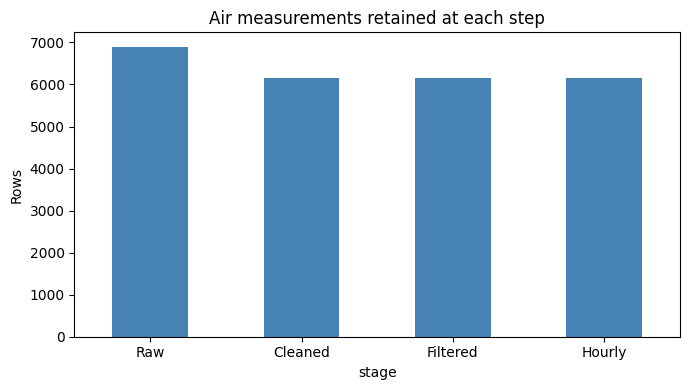

In [12]:
# Average existing readings per sensor-hour. Do not add or fill missing hours.
air_hourly = air_data.copy()
air_hourly["time"] = air_hourly["time"].dt.floor("h")
air_hourly = air_hourly.groupby(
    ["source", "site_id", "latitude", "longitude", "time"], as_index=False
)["pm25"].mean()
print("Before hourly averaging:")
display(air_data.head())
print("After hourly averaging:")
display(air_hourly.head())
row_summary = pd.DataFrame({
    "stage": ["Raw", "Cleaned", "Filtered", "Hourly"],
    "rows": [len(openaq_raw) + len(purpleair_raw), len(openaq_clean) + len(purpleair_clean), len(air_data), len(air_hourly)],
})
display(row_summary)
row_summary.plot.bar(x="stage", y="rows", legend=False, color="steelblue", figsize=(7, 4))
plt.title("Air measurements retained at each step")
plt.ylabel("Rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Basic weather cleaning. Leave missing values unfilled.
limits = {
    "temperature": (-30, 60), "humidity": (0, 100), "rain": (0, 500),
    "wind_speed": (0, 250), "pressure": (850, 1100),
}
weather_columns = [column for column in limits if column in weather_raw]
weather = weather_raw.drop_duplicates().copy()
for column in weather_columns:
    low, high = limits[column]
    weather[column] = pd.to_numeric(weather[column], errors="coerce")
    weather[column] = weather[column].where(weather[column].between(low, high))
print("Weather rows before / after removing duplicates:", len(weather_raw), "/", len(weather))
print("Before:")
display(weather_raw[["station_id", "time"] + weather_columns].head())
print("After:")
display(weather[["station_id", "time"] + weather_columns].head())
display(pd.DataFrame({"missing_before": weather_raw[weather_columns].isna().sum(),
                      "missing_after": weather[weather_columns].isna().sum()}))

Weather rows before / after removing duplicates: 2976 / 2976
Before:


,station_id,time,temperature,humidity,rain,wind_speed,pressure
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,6.1,1010.8
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,0.0,1010.4
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,6.8,1010.5
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,6.1,1009.5
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,0.0,1009.6


After:


,station_id,time,temperature,humidity,rain,wind_speed,pressure
0,96739,2023-12-31 17:00:00+00:00,24.5,97,0.0,6.1,1010.8
1,96739,2023-12-31 18:00:00+00:00,24.2,98,0.0,0.0,1010.4
2,96739,2023-12-31 19:00:00+00:00,24.7,96,0.8,6.8,1010.5
3,96739,2023-12-31 20:00:00+00:00,24.9,96,0.2,6.1,1009.5
4,96739,2023-12-31 21:00:00+00:00,24.3,97,0.0,0.0,1009.6


,missing_before,missing_after
temperature,0,0
humidity,0,0
rain,744,744
wind_speed,0,0
pressure,0,0


In [14]:
# Choose the closest available weather station to the Jakarta centre.
# Meteostat's distance column is in metres and was supplied with station metadata.
available_ids = weather.loc[weather[weather_columns].notna().any(axis=1), "station_id"].unique()
available_stations = weather_stations.loc[weather_stations["station_id"].isin(available_ids)].sort_values("distance")
if available_stations.empty:
    raise ValueError("No station has weather observations for this period")
print("Available stations (nearest first):")
display(available_stations[["station_id", "name", "distance"]])
selected_station = available_stations.iloc[0]["station_id"]
city_weather = weather.loc[weather["station_id"].eq(selected_station), ["time", "station_id"] + weather_columns].copy()
print("Selected station:", selected_station, "Weather rows:", len(city_weather))
display(city_weather.head())

Available stations (nearest first):


,station_id,name,distance
0,96745,Jakarta / Observatory,3144.6
2,96747,Jakarta Halim Perdanakusuma,7559.6
3,96741,Jakarta / Tanjung Priok,12320.8
4,96739,Curug / Budiarto,21792.6


Selected station: 96745 Weather rows: 744


,time,station_id,temperature,humidity,rain,wind_speed,pressure
1490,2023-12-31 17:00:00+00:00,96745,24.7,97,0.0,6.1,1010.7
1491,2023-12-31 18:00:00+00:00,96745,26.7,86,0.0,0.0,1009.5
1492,2023-12-31 19:00:00+00:00,96745,24.9,95,1.2,6.5,1010.4
1493,2023-12-31 20:00:00+00:00,96745,24.9,96,0.6,6.1,1009.5
1494,2023-12-31 21:00:00+00:00,96745,26.8,86,0.3,0.0,1008.8


In [15]:
# Add city-level weather to each air measurement using UTC hour.
print("Air data before the merge:")
display(air_hourly.head())
integrated = air_hourly.merge(city_weather, on="time", how="left", validate="many_to_one")
print("Shape before / after merge:", air_hourly.shape, "/", integrated.shape)
print("Data after the merge:")
display(integrated.head())
print("Missing weather values after matching:")
display(integrated[weather_columns].isna().sum().to_frame("missing"))

Air data before the merge:


,source,site_id,latitude,longitude,time,pm25
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.0
1,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 18:00:00+00:00,134.0
2,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 19:00:00+00:00,134.0
3,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 20:00:00+00:00,105.0
4,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 21:00:00+00:00,87.5


Shape before / after merge: (6159, 6) / (6159, 12)
Data after the merge:


,source,site_id,latitude,longitude,time,pm25,station_id,temperature,humidity,rain,wind_speed,pressure
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.0,96745,24.7,97,0.0,6.1,1010.7
1,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 18:00:00+00:00,134.0,96745,26.7,86,0.0,0.0,1009.5
2,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 19:00:00+00:00,134.0,96745,24.9,95,1.2,6.5,1010.4
3,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 20:00:00+00:00,105.0,96745,24.9,96,0.6,6.1,1009.5
4,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 21:00:00+00:00,87.5,96745,26.8,86,0.3,0.0,1008.8


Missing weather values after matching:


,missing
temperature,0
humidity,0
rain,0
wind_speed,0
pressure,0


,temperature,humidity,rain,wind_speed,pressure
temperature,1.000000,-0.949739,-0.141198,0.162782,-0.256167
humidity,-0.949739,1.000000,0.189640,-0.299805,0.256494
rain,-0.141198,0.189640,1.000000,-0.006791,0.078084
wind_speed,0.162782,-0.299805,-0.006791,1.000000,-0.186117
pressure,-0.256167,0.256494,0.078084,-0.186117,1.000000


Columns removed: []
Shape before / after: (6159, 12) / (6159, 12)


,source,site_id,latitude,longitude,time,pm25,station_id,temperature,humidity,rain,wind_speed,pressure
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.00,96745,24.7,97,0.0,6.1,1010.7
1,OpenAQ,OpenAQ_14313805,-6.096695,106.960983,2023-12-31 17:00:00+00:00,169.00,96745,24.7,97,0.0,6.1,1010.7
2,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,2023-12-31 17:00:00+00:00,133.00,96745,24.7,97,0.0,6.1,1010.7
3,OpenAQ,OpenAQ_6939684,-6.361241,106.841948,2023-12-31 17:00:00+00:00,224.00,96745,24.7,97,0.0,6.1,1010.7
4,PurpleAir,PurpleAir_152230,-6.094740,106.793090,2023-12-31 17:00:00+00:00,330.25,96745,24.7,97,0.0,6.1,1010.7


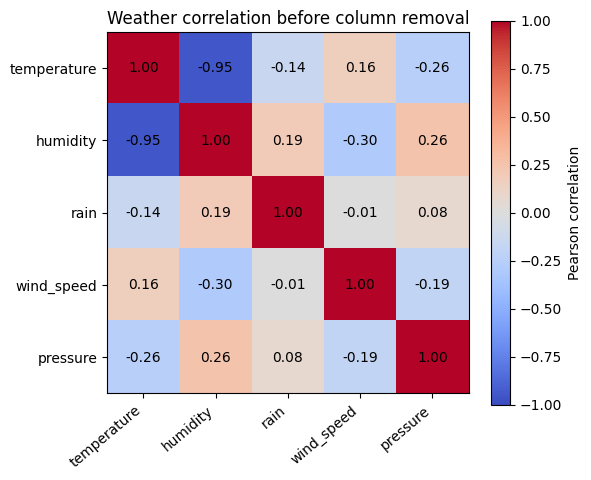

In [16]:
# Check weather redundancy once per hour, without repeating rows for air sensors.
correlation = city_weather[weather_columns].corr()
display(correlation)
# Use a plain loop instead of a matrix mask.
drop_columns = []
for i, column in enumerate(weather_columns):
    for earlier in weather_columns[:i]:
        if earlier not in drop_columns and abs(correlation.loc[column, earlier]) > 0.95:
            drop_columns.append(column)
            break
analysis_ready = integrated.drop(columns=drop_columns).sort_values(["time", "source", "site_id"]).reset_index(drop=True)
print("Columns removed:", drop_columns)
print("Shape before / after:", integrated.shape, "/", analysis_ready.shape)
display(analysis_ready.head())

fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(weather_columns)), weather_columns, rotation=40, ha="right")
ax.set_yticks(range(len(weather_columns)), weather_columns)
for i in range(len(weather_columns)):
    for j in range(len(weather_columns)):
        value = correlation.iloc[i, j]
        ax.text(j, i, "N/A" if pd.isna(value) else f"{value:.2f}", ha="center", va="center")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
ax.set_title("Weather correlation before column removal")
plt.tight_layout()
plt.show()

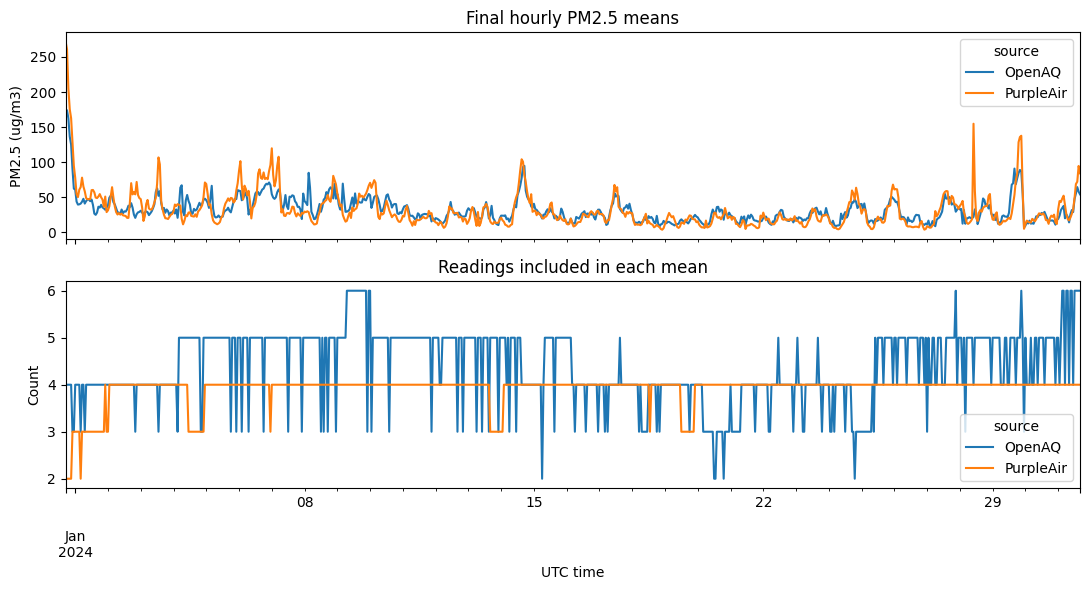

Final shape: (6159, 12)


,source,site_id,latitude,longitude,time,pm25,station_id,temperature,humidity,rain,wind_speed,pressure
0,OpenAQ,OpenAQ_14313802,-6.214719,106.944138,2023-12-31 17:00:00+00:00,155.00,96745,24.7,97,0.0,6.1,1010.7
1,OpenAQ,OpenAQ_14313805,-6.096695,106.960983,2023-12-31 17:00:00+00:00,169.00,96745,24.7,97,0.0,6.1,1010.7
2,OpenAQ,OpenAQ_5077558,-6.236704,106.793244,2023-12-31 17:00:00+00:00,133.00,96745,24.7,97,0.0,6.1,1010.7
3,OpenAQ,OpenAQ_6939684,-6.361241,106.841948,2023-12-31 17:00:00+00:00,224.00,96745,24.7,97,0.0,6.1,1010.7
4,PurpleAir,PurpleAir_152230,-6.094740,106.793090,2023-12-31 17:00:00+00:00,330.25,96745,24.7,97,0.0,6.1,1010.7


,pm25,temperature,humidity,rain,wind_speed,pressure
count,6159.000000,6159.000000,6159.000000,6159.000000,6159.000000,6159.000000
mean,31.667936,27.366374,82.586784,0.439081,10.931888,1010.434632
std,26.240228,2.420977,10.877132,1.112259,7.208249,1.980346
min,0.600000,23.200000,48.000000,0.000000,0.000000,1006.100000
25%,15.075000,25.300000,74.000000,0.000000,6.100000,1009.000000
50%,25.100000,27.000000,84.000000,0.000000,10.800000,1010.300000
75%,41.100000,29.200000,92.000000,0.300000,16.200000,1011.700000
max,551.600000,34.600000,99.000000,10.100000,37.100000,1015.400000


In [17]:
# Final overview: hourly source means and the available readings behind them.
hourly_mean = analysis_ready.groupby(["time", "source"])["pm25"].mean().unstack()
hourly_count = analysis_ready.groupby(["time", "source"])["pm25"].count().unstack()
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
hourly_mean.plot(ax=axes[0])
hourly_count.plot(ax=axes[1])
axes[0].set(title="Final hourly PM2.5 means", ylabel="PM2.5 (ug/m3)")
axes[1].set(title="Readings included in each mean", ylabel="Count", xlabel="UTC time")
plt.tight_layout()
plt.show()
print("Final shape:", analysis_ready.shape)
display(analysis_ready.head())
display(analysis_ready[["pm25"] + [column for column in weather_columns if column in analysis_ready]].describe())